# Industry Project: Inventory Control with Reinforcement Learning (Production-Style)

> **Who is this notebook for?** Someone who has seen what RL is (agent, state, action, reward) and maybe trained an agent on
> CartPole, and now wonders: *how would a company actually use RL for a real operations decision, and is it worth it?*
> No math is required: every step is explained in plain English and almost every line of code has a comment.

---

### How this notebook is different from the others in `11_Reinforcement_Learning/`

| `04_deep_q_networks.ipynb`, `05_policy_gradient.ipynb`, `projects/` | This notebook |
|---|---|
| Ready-made toy environments (CartPole, GridWorld, LunarLander) | A **custom `gymnasium` environment** for a real business problem: warehouse inventory |
| Algorithms written from scratch to understand them | A maintained library (**stable-baselines3**), as used in practice |
| Success = "the reward curve goes up" | Success = **lower cost than a well-tuned classical policy**, measured on the **same random seeds** with **confidence intervals** |
| - | Reward-design pitfalls, robustness to change, saving/loading, **guardrails, shadow mode** and tests before going live |

---

### The business problem

You work for a distributor. One warehouse sells a popular product (think pallets of bottled water) to shops every day.
Every morning the planner decides **how many units to order from the supplier**. Orders arrive **3 days later**.

| Cost | Value | Why |
|---|---|---|
| Holding cost | $1 per unit left in the warehouse per night | space, capital, damage |
| Lost-sale cost | $15 per unit of demand we could not serve | lost margin + annoyed customers (they buy elsewhere) |
| Fixed order cost | $40 per order placed | a truck has to drive, whatever its load |

Orders come in **multiples of 10** (case packs), at most **80 per day** (one truck). Daily demand is random, with a weekly
pattern (busier on Fridays and weekends).

Today the company uses a classical **(s, S) policy**. A consultant says "reinforcement learning will cut costs".
**Your job:** find out honestly whether it does, how big the gain is, how sure we are, and how you would deploy it safely.

### Table of Contents
1. Setup and config
2. Describe the problem as an MDP and build a `gymnasium` environment
3. Classical baselines: base-stock and (s, S) policies
4. Tune the classical policies by simulation (the strong baseline)
5. Reward design: pitfalls that silently ruin RL projects
6. Train PPO with stable-baselines3
7. Fair evaluation: same seeds, confidence intervals, paired comparison
8. Look inside the learned policy
9. Robustness: what if demand changes?
10. Save and load the policy
11. Safe deployment: guardrails and shadow mode
12. Automated tests
13. Summary, exercises and resources

---
## 1. Setup and config

RL results depend on random seeds much more than supervised learning does. We fix seeds everywhere and keep **three
separate sets of seeds**, just like train/validation/test in supervised learning:

- **tuning / training seeds** to tune the classical policy and train the agent,
- **validation seeds** to pick the best agent checkpoint during training,
- **test seeds**, used **once** at the end to compare all policies.

In [1]:
# ---- Standard library ----
import json, logging, tempfile, time, warnings
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path

# ---- Third-party ----
import gymnasium as gym                                  # the standard RL environment API (successor of OpenAI Gym)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import stable_baselines3 as sb3
import torch
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env       # catches common environment bugs
from scipy import stats                                  # confidence intervals
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import EvalCallback
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.monitor import Monitor

warnings.filterwarnings("ignore")
torch.set_num_threads(1)              # tiny networks train faster on one CPU thread (and we share the machine)
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
logging.getLogger("matplotlib").setLevel(logging.WARNING)      # keep matplotlib's own messages quiet
log = logging.getLogger("inventory_rl")


@dataclass(frozen=True)
class EnvConfig:
    lead_time: int = 3                 # days between ordering and delivery
    episode_days: int = 90             # one episode = one quarter
    holding_cost: float = 1.0          # $ per unit in stock per night
    lost_sale_cost: float = 15.0       # $ per unit of unmet demand
    order_fixed_cost: float = 40.0     # $ per order (truck)
    order_step: int = 10               # case pack size
    max_order: int = 80                # truck capacity
    capacity: int = 200                # warehouse can hold at most 200 units
    base_demand: float = 11.0          # average demand on a normal weekday
    demand_multiplier: float = 1.0     # used later to simulate a demand change
    reward_scale: float = 100.0        # reward = -cost / 100 (keeps rewards in a range neural nets like)


@dataclass(frozen=True)
class TrainConfig:
    total_timesteps: int = 200_000     # ~2,200 simulated quarters; a few minutes on one CPU core
    n_envs: int = 8                    # parallel copies of the environment
    seed: int = 0
    tuning_seeds: range = range(0, 200)
    validation_seeds: range = range(5_000, 5_030)
    test_seeds: range = range(10_000, 10_300)


ENV_CFG, TRAIN_CFG = EnvConfig(), TrainConfig()
log.info("gymnasium %s | stable-baselines3 %s | torch %s", gym.__version__, sb3.__version__, torch.__version__)

2026-10-21 17:12:54,299 | INFO | gymnasium 1.4.0 | stable-baselines3 2.9.0 | torch 2.12.1+cpu


---
## 2. Describe the problem as an MDP and build a `gymnasium` environment

Before writing any RL code, write the problem down as a **Markov Decision Process** (see `01_rl_fundamentals.ipynb`).
This step is where most real RL projects succeed or fail.

| MDP part | Our choice | Why |
|---|---|---|
| **State** (what the agent sees) | stock on hand, the orders still on the way (arriving in 1 and 2 days), the inventory position, day of the week | Everything that matters for the future must be in the state (Markov property). Forgetting the in-transit orders is a classic bug: the agent would re-order what is already coming. |
| **Action** | order 0, 10, 20, ..., 80 units (9 choices) | The real business constraints (case packs, truck size) are built into the action space, so the agent **cannot** propose an impossible order. |
| **Transition** | delivery arrives -> demand happens -> sales and lost sales -> costs | The order of events matters; write it down and test it. |
| **Reward** | `-(holding + lost sales + order cost) / 100` | We **minimise cost** = maximise negative cost. |
| **Episode** | 90 days, then **truncated** (time limit, not a real "end") | Inventory never really ends; telling the algorithm "truncated" (not "terminated") lets it keep valuing the future. |

The environment follows the `gymnasium` API: `reset(seed)` returns `(observation, info)`, `step(action)` returns
`(observation, reward, terminated, truncated, info)`. Business numbers (costs, demand) go into `info` so we can analyse them.

In [2]:
class InventoryEnv(gym.Env):
    """One product, one warehouse, daily ordering with lead time and lost sales."""

    metadata = {"render_modes": []}
    WEEKDAY_FACTOR = np.array([1.0, 0.9, 0.9, 1.0, 1.15, 1.4, 1.25])     # Mon..Sun demand pattern

    def __init__(self, cfg: EnvConfig = ENV_CFG):
        self.cfg = cfg
        self.order_sizes = np.arange(0, cfg.max_order + 1, cfg.order_step)   # [0, 10, ..., 80]
        self.action_space = spaces.Discrete(len(self.order_sizes))
        # observation: on_hand, arriving in 1 day, arriving in 2 days, inventory position (all /100), sin/cos(weekday)
        self.observation_space = spaces.Box(low=-1.0, high=5.0, shape=(cfg.lead_time + 3,), dtype=np.float32)

    # ---- helpers ----
    @property
    def inventory_position(self) -> float:
        """Stock on hand + everything already ordered but not yet delivered."""
        return self.on_hand + self.pipeline.sum()

    def _observation(self) -> np.ndarray:
        weekday = self.day % 7
        return np.array([self.on_hand / 100, *(self.pipeline[1:] / 100), self.inventory_position / 100,
                         np.sin(2 * np.pi * weekday / 7), np.cos(2 * np.pi * weekday / 7)], dtype=np.float32)

    # ---- gymnasium API ----
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)                                     # seeds self.np_random (reproducible demand)
        self.day = int(self.np_random.integers(0, 7))                # start on a random weekday
        self.t = 0
        self.on_hand = float(self.np_random.integers(20, 61))         # random starting stock
        self.pipeline = np.zeros(self.cfg.lead_time)                 # pipeline[0] arrives today, [1] tomorrow, ...
        return self._observation(), {}

    def step(self, action):
        order = float(self.order_sizes[int(action)])
        # 1. today's delivery arrives (anything above capacity cannot be stored and is lost)
        received = self.pipeline[0]
        overflow = max(0.0, self.on_hand + received - self.cfg.capacity)
        self.on_hand = self.on_hand + received - overflow
        # 2. the new order joins the end of the pipeline (arrives in `lead_time` days)
        self.pipeline = np.append(self.pipeline[1:], order)
        # 3. customers arrive: random demand with a weekly pattern and day-to-day noise
        mean = (self.cfg.base_demand * self.cfg.demand_multiplier * self.WEEKDAY_FACTOR[self.day % 7]
                * self.np_random.gamma(5.0, 0.2))
        demand = float(self.np_random.poisson(mean))
        sold = min(self.on_hand, demand)
        lost = demand - sold
        self.on_hand -= sold
        # 4. costs of the day
        holding = self.cfg.holding_cost * self.on_hand
        lost_cost = self.cfg.lost_sale_cost * (lost + overflow)          # wasted overflow is as bad as a lost sale
        order_cost = self.cfg.order_fixed_cost if order > 0 else 0.0
        cost = holding + lost_cost + order_cost
        self.t += 1
        self.day += 1
        truncated = self.t >= self.cfg.episode_days                     # time limit, NOT a terminal state
        info = {"cost": cost, "holding": holding, "lost_sales": lost_cost, "ordering": order_cost,
                "demand": demand, "lost_units": lost, "order": order, "on_hand": self.on_hand}
        return self._observation(), -cost / self.cfg.reward_scale, False, truncated, info


env = InventoryEnv()
check_env(env)                                                            # raises if the API is used wrongly
print("check_env passed. Action space:", env.action_space, "| order sizes:", env.order_sizes)

# Walk through 3 days by hand: always the first thing to do with a new environment
obs, _ = env.reset(seed=1)
print("start obs:", obs.round(2))
for action in [4, 0, 0]:                                                  # order 40, then nothing
    obs, reward, terminated, truncated, info = env.step(action)
    print(f"order {info['order']:>4.0f} | demand {info['demand']:>3.0f} | on hand {info['on_hand']:>4.0f} "
          f"| cost ${info['cost']:>6.1f} | reward {reward:+.3f}")

check_env passed. Action space: Discrete(9) | order sizes: [ 0 10 20 30 40 50 60 70 80]
start obs: 

[ 0.4   0.    0.    0.4   0.43 -0.9 ]
order   40 | demand  23 | on hand   17 | cost $  57.0 | reward -0.570
order    0 | demand  13 | on hand    4 | cost $   4.0 | reward -0.040
order    0 | demand  17 | on hand    0 | cost $ 195.0 | reward -1.950


---
## 3. Classical baselines: base-stock and (s, S) policies

Operations research solved problems like this decades ago. Two classic policies, both based on the
**inventory position** (stock on hand + stock on the way):

- **Base-stock (order-up-to S)**: every day, order enough to bring the position back up to `S`.
  Optimal when there is no fixed order cost.
- **(s, S) policy** (Scarf, 1960): only order when the position falls **at or below `s`**, and then order up to `S`.
  The gap between `s` and `S` avoids paying the $40 truck cost every day. With fixed costs this family is known to be
  optimal or near-optimal for many inventory problems.

Both obey the same rules as the agent (multiples of 10, at most 80 per order). We also add a **naive** policy
(order the average demand every day) to show what "no thinking" costs.

To compare policies **fairly**, every policy is run on exactly the **same seeds**: the same customers on the same days
(this is called **common random numbers**). Differences in cost are then due to the policy, not to luck.

In [3]:
def to_action(env: InventoryEnv, quantity: float) -> int:
    """Round a wanted quantity to the nearest allowed order size and return its action index."""
    return int(np.clip(np.round(quantity / env.cfg.order_step), 0, len(env.order_sizes) - 1))


def naive_policy(env, obs):
    return to_action(env, env.cfg.base_demand)                     # order ~average demand, every day


def base_stock_policy(S):
    def policy(env, obs):
        return to_action(env, S - env.inventory_position)          # bring the position back to S
    policy.__name__ = f"base_stock(S={S})"
    return policy


def s_S_policy(s, S):
    def policy(env, obs):
        if env.inventory_position <= s:                            # only order when we are low
            return to_action(env, S - env.inventory_position)
        return 0
    policy.__name__ = f"(s={s}, S={S})"
    return policy


def run_episodes(policy, seeds, cfg: EnvConfig = ENV_CFG) -> pd.DataFrame:
    """Simulate one 90-day episode per seed; return the cost breakdown per episode."""
    env, rows = InventoryEnv(cfg), []
    for seed in seeds:
        obs, _ = env.reset(seed=int(seed))
        totals = {"seed": seed, "cost": 0.0, "holding": 0.0, "lost_sales": 0.0, "ordering": 0.0,
                  "demand": 0.0, "lost_units": 0.0}
        done = False
        while not done:
            obs, _, terminated, truncated, info = env.step(policy(env, obs))
            for key in ["cost", "holding", "lost_sales", "ordering", "demand", "lost_units"]:
                totals[key] += info[key]
            done = terminated or truncated
        rows.append(totals)
    out = pd.DataFrame(rows)
    out["fill_rate"] = 1 - out["lost_units"] / out["demand"]
    return out


naive_costs = run_episodes(naive_policy, TRAIN_CFG.tuning_seeds)
print(f"Naive policy: average cost per quarter ${naive_costs['cost'].mean():,.0f}, fill rate {naive_costs['fill_rate'].mean():.1%}")

Naive policy: average cost per quarter $6,814, fill rate 84.4%


---
## 4. Tune the classical policies by simulation (the strong baseline)

A classical policy is only a fair opponent if its parameters are **tuned as carefully as the RL agent**. Comparing a
fine-tuned neural network with a guessed `(s, S)` is the most common way RL "wins" in blog posts.

The simulator makes tuning easy: try every sensible `(s, S)` pair on the 200 tuning seeds and keep the cheapest.
This takes seconds and needs no neural network.

2026-10-21 17:16:24,283 | INFO | grid search took 101s


best (s,S) = (50, 80): $4,224 per quarter


best base-stock S = 60: $5,352 per quarter


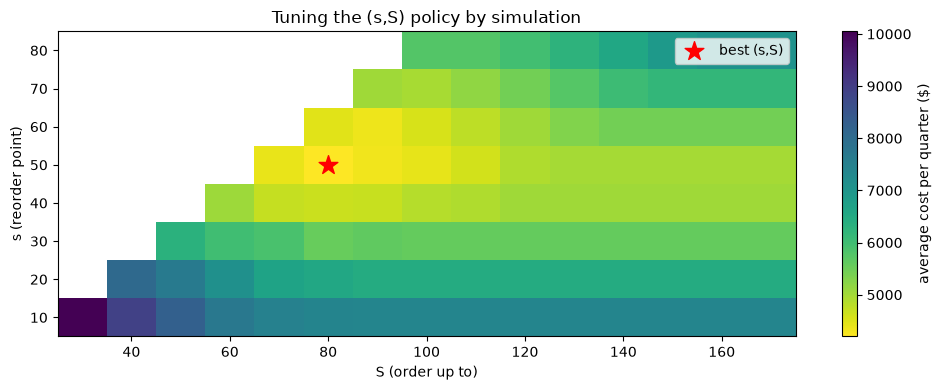

1 of 92 (s,S) pairs are within 3% of the best cost on the tuning seeds


In [4]:
start = time.time()
grid = []
for s in range(10, 81, 10):                                   # reorder point candidates
    for S in range(s + 20, 171, 10):                          # order-up-to candidates (S > s)
        grid.append({"s": s, "S": S, "cost": run_episodes(s_S_policy(s, S), TRAIN_CFG.tuning_seeds[:50])["cost"].mean()})
grid = pd.DataFrame(grid)
best_sS = grid.loc[grid["cost"].idxmin()]
base_grid = pd.DataFrame([{"S": S, "cost": run_episodes(base_stock_policy(S), TRAIN_CFG.tuning_seeds[:50])["cost"].mean()}
                          for S in range(30, 131, 10)])
best_S = base_grid.loc[base_grid["cost"].idxmin()]
log.info("grid search took %.0fs", time.time() - start)

# Confirm the winners on all 200 tuning seeds (the grid used the first 50 to save time)
S_S = (int(best_sS["s"]), int(best_sS["S"]))
BASE_S = int(best_S["S"])
print(f"best (s,S) = {S_S}: ${run_episodes(s_S_policy(*S_S), TRAIN_CFG.tuning_seeds)['cost'].mean():,.0f} per quarter")
print(f"best base-stock S = {BASE_S}: ${run_episodes(base_stock_policy(BASE_S), TRAIN_CFG.tuning_seeds)['cost'].mean():,.0f} per quarter")

pivot = grid.pivot(index="s", columns="S", values="cost")
plt.figure(figsize=(10, 4))
plt.imshow(pivot.values, aspect="auto", cmap="viridis_r", origin="lower",
           extent=[pivot.columns.min() - 5, pivot.columns.max() + 5, pivot.index.min() - 5, pivot.index.max() + 5])
plt.colorbar(label="average cost per quarter ($)")
plt.scatter([S_S[1]], [S_S[0]], color="red", marker="*", s=200, label="best (s,S)")
plt.xlabel("S (order up to)"); plt.ylabel("s (reorder point)"); plt.title("Tuning the (s,S) policy by simulation")
plt.legend(); plt.tight_layout(); plt.show()
near_best = (grid["cost"] <= 1.03 * best_sS["cost"]).sum()
print(f"{near_best} of {len(grid)} (s,S) pairs are within 3% of the best cost on the tuning seeds")

Look at the printed line under the heat map: only **1 of the 92** `(s, S)` pairs is within 3% of the best cost. With a
3-day lead time, lost sales and a $40 truck, the valley is **narrow**: a reorder point 10 units too low already causes
many more stock-outs. So a *guessed* `(s, S)` is a weak opponent, and tuning it by simulation (a minute of CPU) is
essential before comparing it with anything fancier.

---
## 5. Reward design: pitfalls that silently ruin RL projects

The agent optimises **exactly** the reward you give it, not what you meant. Common traps in operations problems:

| Pitfall | What happens |
|---|---|
| Reward only penalises stock-outs ("customers must never wait") | The agent learns to **order the maximum every day**: perfect service, ruinous holding cost |
| Reward = revenue only | Same: buying more stock never hurts the reward |
| Rewards in raw dollars (-500 per day) | Value-function targets are huge; learning becomes unstable. Scale them (we divide by 100) |
| Only a reward at the end of the quarter | The agent cannot tell which of the 90 decisions were good (credit assignment). Give the cost every day |
| Day counter in the state + "terminated" at day 90 | The agent learns to stop ordering near the end ("the world ends tomorrow"). Use `truncated` and leave the counter out |
| Ignoring constraints in the reward instead of the action space | The agent finds "creative" actions that break business rules |

We can see the first trap without training anything: just score simple policies with the "stock-outs only" reward.

In [5]:
candidates = {"order max (80) every day": lambda env, obs: len(env.order_sizes) - 1,
              f"tuned (s,S) {S_S}": s_S_policy(*S_S),
              "naive (11/day)": naive_policy}
rows = []
for name, policy in candidates.items():
    r = run_episodes(policy, TRAIN_CFG.tuning_seeds[:50])
    rows.append({"policy": name, "stockout-only reward (higher=better)": -r["lost_sales"].mean() / 100,
                 "true total cost $": r["cost"].mean(), "fill rate": r["fill_rate"].mean()})
pd.DataFrame(rows).set_index("policy").round(3)

,stockout-only reward (higher=better),true total cost $,fill rate
policy,,,
order max (80) every day,-862.521,106119.62,0.996
"tuned (s,S) (50, 80)",-9.339,4199.12,0.943
naive (11/day),-24.915,6750.74,0.847


With the wrong reward, "order the maximum every day" is the **best** policy (no stock-outs, so a top score), yet it
costs about 25 times more than the tuned `(s, S)` policy in reality (most of the stock overflows the warehouse or sits
there). An RL agent trained on that reward would find this policy, and its training curve would look great.
**Always evaluate an agent on the true business KPI, not only on its reward.**

---
## 6. Train PPO with stable-baselines3

**PPO** (Proximal Policy Optimization, see `05_policy_gradient.ipynb`) is the usual first choice: stable, works with
discrete actions, few hyperparameters to tune. Key industry practices in the code below:

- **Vectorised environments** (`make_vec_env`, 8 copies) collect experience faster.
- `Monitor` wrappers record episode rewards for logging.
- An **`EvalCallback`** regularly evaluates the agent on the **validation seeds** and saves the **best checkpoint**:
  RL training is noisy and the last model is not always the best one.
- A small network (`[64, 64]`) and a modest budget of 200,000 steps: on CPU this takes about 3-6 minutes depending on
  the machine and how busy it is. While preparing this notebook we also tried 120,000 steps: that agent was still slightly **worse** than
  the tuned (s, S) policy. The budget matters, and the classical baseline needs none.
  Real projects run many seeds and hyperparameter searches (e.g. with Optuna and the RL Baselines3 Zoo).

2026-10-21 17:22:20,239 | INFO | PPO trained for 200000 steps in 328s


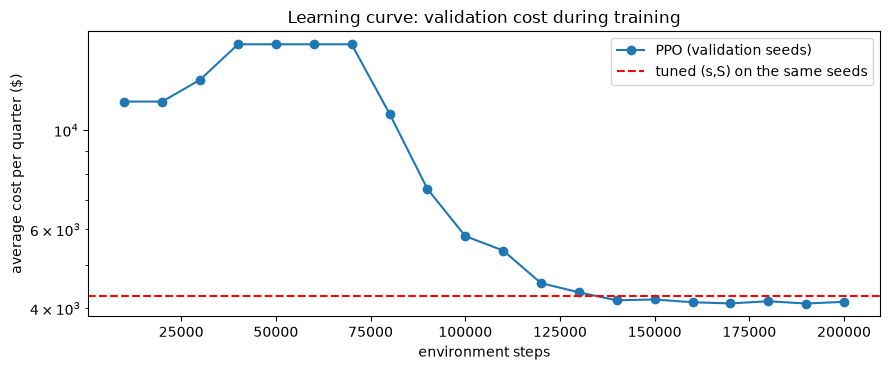

best validation cost: PPO $4,100 vs (s,S) $4,264


In [6]:
RUN_DIR = Path(tempfile.mkdtemp(prefix="inventory_rl_"))     # in real life: models/inventory_ppo/v1/


class FixedSeedsEnv(InventoryEnv):
    """Validation env: cycles through a fixed list of seeds, so every evaluation sees the same quarters."""

    def __init__(self, seeds, cfg: EnvConfig = ENV_CFG):
        super().__init__(cfg)
        self._seeds, self._i = list(seeds), 0

    def reset(self, seed=None, options=None):
        seed = self._seeds[self._i % len(self._seeds)]
        self._i += 1
        return super().reset(seed=seed)


train_env = make_vec_env(InventoryEnv, n_envs=TRAIN_CFG.n_envs, seed=TRAIN_CFG.seed)   # random quarters
eval_env = Monitor(FixedSeedsEnv(TRAIN_CFG.validation_seeds))
eval_callback = EvalCallback(eval_env, n_eval_episodes=len(TRAIN_CFG.validation_seeds),
                             eval_freq=10_000 // TRAIN_CFG.n_envs,              # every 10k environment steps
                             best_model_save_path=str(RUN_DIR / "best"), log_path=str(RUN_DIR),   # saves evaluations.npz
                             deterministic=True, verbose=0)

model = PPO("MlpPolicy", train_env,
            n_steps=512,                 # steps per env before each update (8 x 512 = 4096 transitions)
            batch_size=512, n_epochs=10, learning_rate=3e-4,
            gamma=0.99,                  # values costs ~100 days ahead: longer than the 3-day lead time
            gae_lambda=0.95, ent_coef=0.01,   # a little entropy keeps exploring order sizes
            policy_kwargs=dict(net_arch=[64, 64]), seed=TRAIN_CFG.seed, verbose=0)
start = time.time()
model.learn(total_timesteps=TRAIN_CFG.total_timesteps, callback=eval_callback)
TRAIN_SECONDS = time.time() - start
log.info("PPO trained for %d steps in %.0fs", TRAIN_CFG.total_timesteps, TRAIN_SECONDS)

evals = pd.DataFrame({"timesteps": eval_callback.evaluations_timesteps,
                      "validation_cost": -np.mean(eval_callback.evaluations_results, axis=1) * ENV_CFG.reward_scale})
sS_validation = run_episodes(s_S_policy(*S_S), TRAIN_CFG.validation_seeds)["cost"].mean()
plt.figure(figsize=(9, 3.8))
plt.plot(evals["timesteps"], evals["validation_cost"], marker="o", label="PPO (validation seeds)")
plt.axhline(sS_validation, color="red", ls="--", label=f"tuned (s,S) on the same seeds")
plt.xlabel("environment steps"); plt.ylabel("average cost per quarter ($)"); plt.yscale("log")
plt.title("Learning curve: validation cost during training"); plt.legend(); plt.tight_layout(); plt.show()
print(f"best validation cost: PPO ${evals['validation_cost'].min():,.0f} vs (s,S) ${sS_validation:,.0f}")

---
## 7. Fair evaluation: same seeds, confidence intervals, paired comparison

Now the final exam, on **300 test quarters** that neither the tuning nor the training ever saw.
We load the **best checkpoint** (chosen on validation seeds) and run every policy on the same seeds.

Two statistical tools:
- a **95% confidence interval** for each policy's average cost (how precisely we know it),
- a **paired comparison**: for each seed, cost(PPO) - cost((s,S)). Because both saw the same demand, this difference has
  much less noise than comparing the two averages separately. If its confidence interval contains 0, we **cannot claim**
  that one policy is better.

In [7]:
best_model = PPO.load(RUN_DIR / "best" / "best_model.zip")


def ppo_policy(model):
    def policy(env, obs):
        action, _ = model.predict(obs, deterministic=True)       # deterministic = no exploration at test time
        return int(action)
    return policy


def mean_ci(x: np.ndarray, level: float = 0.95) -> tuple:
    """Mean and t-distribution confidence interval."""
    half = stats.t.ppf((1 + level) / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean(), x.mean() - half, x.mean() + half


POLICIES = {"naive": naive_policy, f"base-stock S={BASE_S}": base_stock_policy(BASE_S),
            f"(s,S) {S_S}": s_S_policy(*S_S), "PPO (best checkpoint)": ppo_policy(best_model)}
test_results = {name: run_episodes(p, TRAIN_CFG.test_seeds) for name, p in POLICIES.items()}

rows = []
for name, r in test_results.items():
    m, lo, hi = mean_ci(r["cost"].values)
    rows.append({"policy": name, "mean cost $": m, "95% CI low": lo, "95% CI high": hi,
                 "holding $": r["holding"].mean(), "lost sales $": r["lost_sales"].mean(),
                 "ordering $": r["ordering"].mean(), "fill rate": r["fill_rate"].mean()})
leaderboard = pd.DataFrame(rows).set_index("policy").round(3)
display(leaderboard)

reference = f"(s,S) {S_S}"
diff = test_results["PPO (best checkpoint)"]["cost"].values - test_results[reference]["cost"].values
m, lo, hi = mean_ci(diff)
print(f"Paired difference PPO - (s,S): {m:+,.0f} $ per quarter  (95% CI {lo:+,.0f} .. {hi:+,.0f})")
print(f"PPO cheaper in {np.mean(diff < 0):.0%} of the {len(diff)} test quarters | relative: {m / test_results[reference]['cost'].mean():+.1%}")

,mean cost $,95% CI low,95% CI high,holding $,lost sales $,ordering $,fill rate
policy,,,,,,,
naive,6859.080,6782.486,6935.674,665.380,2593.70,3600.000,0.842
base-stock S=60,5400.533,5354.476,5446.591,1402.767,1100.30,2897.467,0.933
"(s,S) (50, 80)",4268.567,4223.896,4313.237,2159.683,1001.15,1107.733,0.939
PPO (best checkpoint),4100.633,4058.926,4142.341,2168.483,924.15,1008.000,0.944


Paired difference PPO - (s,S): -168 $ per quarter  (95% CI -205 .. -131)
PPO cheaper in 68% of the 300 test quarters | relative: -3.9%


**How to read this honestly:**
- The **naive** policy (about $6,860 per quarter) is far worse than everything else: any thinking about inventory pays off.
- **Base-stock** (about $5,400) pays the $40 truck almost every day; the tuned **(s, S)** policy (about $4,270) avoids
  that and is a strong baseline.
- **PPO** comes out at about $4,100: the paired difference is about **-$170 per quarter (-4%)**, its 95% confidence interval
  is entirely below 0, and PPO is cheaper in about two thirds of the test quarters. So the gain is **real but small**.
- Where does it come from? Our (s, S) policy ignores the **weekday** (Fridays and weekends are busier) and, with lost sales
  and a 3-day lead time, (s, S) is no longer the provably optimal family. PPO sees the weekday in its state. A
  weekday-dependent heuristic (exercise 2) might close much of the gap at almost no cost.
- Is 4% worth it? On one product, ~$680 a year is not worth a neural network in production. Across 10,000 products it might
  be, **if** the gain survives the robustness and deployment checks below.
- This matches what practitioners and benchmarks such as OR-Gym report: on a single, well-understood inventory problem,
  **RL roughly matches or slightly beats a well-tuned heuristic**. RL becomes really interesting when the problem is too
  complex for classical policies: many products sharing a truck, multi-echelon networks, perishable goods with ages,
  non-stationary demand with many signals, where no simple formula exists.

---
## 8. Look inside the learned policy

A planner will not trust a black box. Two simple views help:
1. **Order decision vs inventory position** (with nothing in transit), compared with the `(s, S)` rule.
2. One **simulated quarter**, side by side.

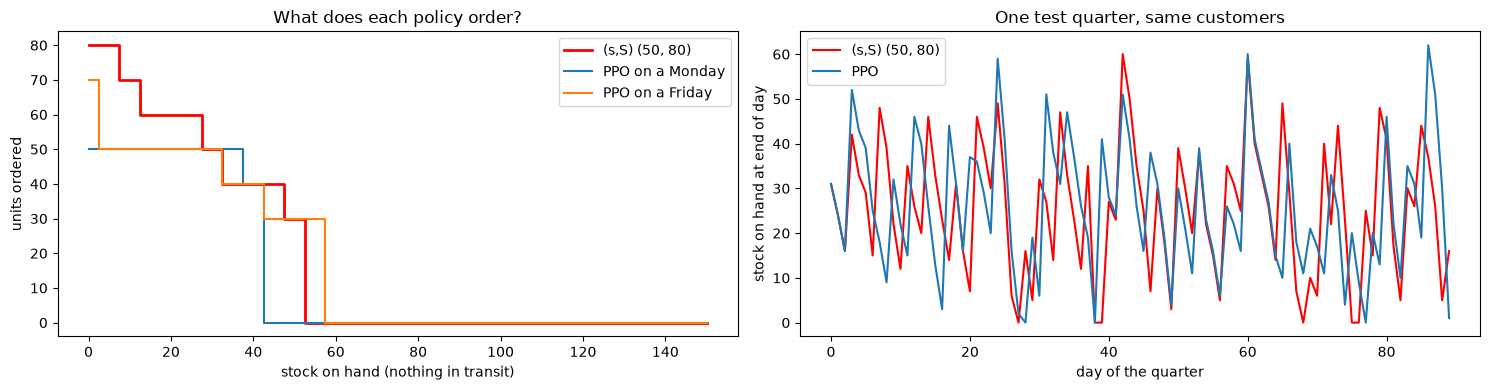

Units ordered by stock on hand (nothing in transit):
            0    10   20   30   40   50   60   70   80   90   100  110  120  130  140  150
(s,S)        80   70   60   50   40   30    0    0    0    0    0    0    0    0    0    0
PPO Monday   50   50   50   50   40    0    0    0    0    0    0    0    0    0    0    0
PPO Friday   70   50   50   50   40   30    0    0    0    0    0    0    0    0    0    0


In [8]:
probe_env = InventoryEnv()
probe_env.reset(seed=0)
positions = np.arange(0, 151, 5)
weekday_orders = {}
for weekday, label in [(0, "Monday"), (4, "Friday")]:
    orders = []
    for pos in positions:
        probe_env.on_hand, probe_env.pipeline, probe_env.day = float(pos), np.zeros(ENV_CFG.lead_time), weekday
        action, _ = best_model.predict(probe_env._observation(), deterministic=True)
        orders.append(probe_env.order_sizes[int(action)])
    weekday_orders[label] = orders
sS_orders = [probe_env.order_sizes[to_action(probe_env, S_S[1] - p)] if p <= S_S[0] else 0 for p in positions]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].step(positions, sS_orders, where="mid", color="red", lw=2, label=f"(s,S) {S_S}")
for label, orders in weekday_orders.items():
    axes[0].step(positions, orders, where="mid", lw=1.5, label=f"PPO on a {label}")
axes[0].set_xlabel("stock on hand (nothing in transit)"); axes[0].set_ylabel("units ordered")
axes[0].set_title("What does each policy order?"); axes[0].legend()

for name, policy, color in [(f"(s,S) {S_S}", s_S_policy(*S_S), "red"), ("PPO", ppo_policy(best_model), "tab:blue")]:
    sim_env = InventoryEnv(); obs, _ = sim_env.reset(seed=TRAIN_CFG.test_seeds[0]); stock = []
    for _ in range(ENV_CFG.episode_days):
        obs, _, _, _, info = sim_env.step(policy(sim_env, obs)); stock.append(info["on_hand"])
    axes[1].plot(stock, color=color, label=name)
axes[1].set_xlabel("day of the quarter"); axes[1].set_ylabel("stock on hand at end of day")
axes[1].set_title("One test quarter, same customers"); axes[1].legend()
plt.tight_layout(); plt.show()
orders_table = pd.DataFrame({"(s,S)": sS_orders, **{f"PPO {k}": v for k, v in weekday_orders.items()}}, index=positions)
print("Units ordered by stock on hand (nothing in transit):")
print(orders_table.loc[::2].T.to_string())

**What the table shows:** PPO learned the same *shape* as `(s, S)`: order when stock is low, order nothing when it is
high. The differences are instructive:
- PPO's reorder point depends on the **weekday**: on a Friday (busy weekend ahead) it already orders at 50 units in stock,
  on a Monday only at 40 or below. The classical policy uses one threshold for every day.
- PPO orders **smaller amounts** when the shelf is empty (50-70 instead of 80): it trades a little more stock-out risk for
  less leftover stock. Whether planners accept that is a business discussion, and exactly the kind of difference that
  shadow mode (section 11) surfaces.
- Odd jumps or "order 80 when stock is high" would have been warning signs of an under-trained agent or of states it rarely
  visited during training. We see none here, but only for these probe states.

---
## 9. Robustness: what if demand changes?

In production, the world changes: a new big customer arrives and demand is suddenly **30% higher**.
Neither policy was designed for that. How do they cope, and how quickly can we fix each one?

In [9]:
shifted_cfg = EnvConfig(demand_multiplier=1.3)
shift_rows = []
for name in [f"(s,S) {S_S}", "PPO (best checkpoint)"]:
    r = run_episodes(POLICIES[name], TRAIN_CFG.test_seeds[:150], cfg=shifted_cfg)
    shift_rows.append({"policy": name, "cost $ (demand +30%)": r["cost"].mean(), "fill rate": r["fill_rate"].mean()})

start = time.time()                                          # re-tuning the classical policy for the new demand
regrid = [{"s": s, "S": S, "cost": run_episodes(s_S_policy(s, S), TRAIN_CFG.tuning_seeds[:40], cfg=shifted_cfg)["cost"].mean()}
          for s in range(S_S[0], S_S[0] + 41, 10) for S in range(max(S_S[1], s + 20), S_S[1] + 61, 10)]   # search upwards
regrid = pd.DataFrame(regrid).sort_values("cost").iloc[0]
retuned = (int(regrid["s"]), int(regrid["S"]))
r = run_episodes(s_S_policy(*retuned), TRAIN_CFG.test_seeds[:150], cfg=shifted_cfg)
shift_rows.append({"policy": f"(s,S) re-tuned {retuned} in {time.time() - start:.0f}s", "cost $ (demand +30%)": r["cost"].mean(),
                   "fill rate": r["fill_rate"].mean()})
pd.DataFrame(shift_rows).set_index("policy").round(3)

,cost $ (demand +30%),fill rate
policy,,
"(s,S) (50, 80)",6095.193,0.847
PPO (best checkpoint),5993.647,0.841
"(s,S) re-tuned (70, 110) in 18s",5170.993,0.955


Both policies get more expensive when demand jumps, because they keep too little stock. The difference is **how fast you
can fix it**: the classical policy is re-tuned by simulation in seconds and is easy to explain ("we raised the reorder
point"). The RL agent needs **retraining** (minutes to hours, with new validation), or must be trained from the start on
a wide range of demand levels with the demand level in its state (*domain randomisation*). Plan for this before going live.

---
## 10. Save and load the policy

stable-baselines3 saves the network weights, the hyperparameters and the optimizer state in one `.zip` file.
We add a JSON file with what the model **cannot** tell you itself: the environment config it was trained on, the training
budget and seeds, and its test results versus the baseline. Without that, nobody can safely reuse the file in six months.

In [10]:
MODEL_PATH = RUN_DIR / "ppo_inventory.zip"
best_model.save(MODEL_PATH)
metadata = {
    "model": "PPO MlpPolicy [64, 64]", "saved_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "stable_baselines3_version": sb3.__version__, "gymnasium_version": gym.__version__,
    "env_config": asdict(ENV_CFG), "train_config": {**asdict(TRAIN_CFG), "tuning_seeds": str(TRAIN_CFG.tuning_seeds),
                                                     "validation_seeds": str(TRAIN_CFG.validation_seeds),
                                                     "test_seeds": str(TRAIN_CFG.test_seeds)},
    "training_seconds": round(TRAIN_SECONDS, 1),
    "baseline_policy": {"type": "(s,S)", "s": S_S[0], "S": S_S[1]},
    "test_results": leaderboard[["mean cost $", "95% CI low", "95% CI high", "fill rate"]].to_dict(orient="index"),
}
(RUN_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str))

loaded = PPO.load(MODEL_PATH, device="cpu")
check_obs = np.stack([InventoryEnv().reset(seed=s)[0] for s in range(20)])
same = np.array_equal(loaded.predict(check_obs, deterministic=True)[0], best_model.predict(check_obs, deterministic=True)[0])
print(f"Saved {MODEL_PATH.name} ({MODEL_PATH.stat().st_size / 1024:.0f} KB) + metadata.json; reloaded model gives identical actions: {same}")

Saved ppo_inventory.zip (146 KB) + metadata.json; reloaded model gives identical actions: True


---
## 11. Safe deployment: guardrails and shadow mode

An RL policy can do something strange in a state it never saw in training. Companies therefore never let a fresh agent
place real orders directly. A typical path:

1. **Offline evaluation** on a simulator and on historical demand (what we did).
2. **Guardrails**: hard business rules wrapped around the agent. If the agent's order breaks a rule, the rule wins and
   the event is logged.
3. **Shadow mode**: the classical policy keeps placing the real orders; the agent only **recommends**, and we log both.
   Planners review large disagreements. (Note: shadow mode cannot measure the agent's cost directly, because its orders
   never happen; that is why the simulator matters.)
4. **Canary / A/B rollout**: the agent controls a small share of products or warehouses, with automatic rollback.
5. **Monitoring**: cost, fill rate, and how often guardrails fire. Frequent guardrail hits = retrain or roll back.

Below is a recommendation service with guardrails and input validation, and a shadow-mode simulation.

In [11]:
class OrderRecommender:
    """Wraps the RL policy with input checks, guardrails and a classical fallback."""

    def __init__(self, model_path: Path, metadata_path: Path):
        self.model = PPO.load(model_path, device="cpu")
        self.meta = json.loads(Path(metadata_path).read_text())
        self.cfg = EnvConfig(**self.meta["env_config"])
        self.s, self.S = self.meta["baseline_policy"]["s"], self.meta["baseline_policy"]["S"]
        self.env = InventoryEnv(self.cfg)                       # used only to build observations
        self.env.reset(seed=0)

    def recommend(self, on_hand: float, in_transit: list, weekday: int) -> dict:
        """in_transit[k] = units arriving k days from now (k=0: this morning's delivery, not yet booked in)."""
        # ---- input validation ----
        if len(in_transit) != self.cfg.lead_time or min([on_hand, *in_transit]) < 0 or not 0 <= weekday <= 6:
            raise ValueError("invalid state: need on_hand >= 0, %d in-transit values >= 0, weekday 0-6" % self.cfg.lead_time)
        self.env.on_hand, self.env.day = float(on_hand), int(weekday)
        self.env.pipeline = np.array(in_transit, dtype=float)
        position = self.env.inventory_position
        fallback = self.env.order_sizes[to_action(self.env, self.S - position)] if position <= self.s else 0.0
        # ---- out-of-distribution check: never trust the agent far outside what it saw in training ----
        if position > self.cfg.capacity or on_hand > self.cfg.capacity:
            return {"order": float(fallback), "source": "fallback (s,S)", "reason": "state outside training range"}
        action, _ = self.model.predict(self.env._observation(), deterministic=True)
        order, reason = float(self.env.order_sizes[int(action)]), "ok"
        # ---- guardrails (business rules always win) ----
        if position + order > self.cfg.capacity:                                    # never plan above capacity
            order, reason = float(self.cfg.order_step * ((self.cfg.capacity - position) // self.cfg.order_step)), "capped at capacity"
        if position <= 0.5 * self.s and order < fallback:                           # emergency: far below reorder point
            order, reason = float(fallback), "raised to (s,S) emergency order"
        return {"order": max(order, 0.0), "source": "PPO", "reason": reason}


recommender = OrderRecommender(MODEL_PATH, RUN_DIR / "metadata.json")
for state in [dict(on_hand=15, in_transit=[0, 0, 0], weekday=4), dict(on_hand=120, in_transit=[0, 0, 20], weekday=1),
              dict(on_hand=500, in_transit=[0, 0, 0], weekday=2)]:
    print(state, "->", recommender.recommend(**state))
try:
    recommender.recommend(on_hand=-3, in_transit=[0, 0, 0], weekday=1)
except ValueError as err:
    print("rejected:", err)

{'on_hand': 15, 'in_transit': [0, 0, 0], 'weekday': 4} -> {'order': 60.0, 'source': 'PPO', 'reason': 'raised to (s,S) emergency order'}
{'on_hand': 120, 'in_transit': [0, 0, 20], 'weekday': 1} -> {'order': 0.0, 'source': 'PPO', 'reason': 'ok'}
{'on_hand': 500, 'in_transit': [0, 0, 0], 'weekday': 2} -> {'order': 0.0, 'source': 'fallback (s,S)', 'reason': 'state outside training range'}
rejected: invalid state: need on_hand >= 0, 3 in-transit values >= 0, weekday 0-6


In [12]:
# Shadow mode: the (s,S) policy places the real orders; the agent's recommendation is only logged
shadow_log = []
live_policy = s_S_policy(*S_S)
for seed in TRAIN_CFG.test_seeds[:20]:                                   # 20 quarters of "live" operation
    live_env = InventoryEnv(); obs, _ = live_env.reset(seed=int(seed)); done = False
    while not done:
        rec = recommender.recommend(live_env.on_hand, list(live_env.pipeline), live_env.day % 7)
        live_action = live_policy(live_env, obs)
        shadow_log.append({"live_order": live_env.order_sizes[live_action], "agent_order": rec["order"],
                           "guardrail": rec["reason"] != "ok", "position": live_env.inventory_position})
        obs, _, terminated, truncated, _ = live_env.step(live_action)
        done = terminated or truncated
shadow = pd.DataFrame(shadow_log)
shadow["disagreement"] = (shadow["agent_order"] - shadow["live_order"]).abs()
print(f"Decisions logged: {len(shadow):,}")
print(f"Same decision as live policy: {(shadow['disagreement'] == 0).mean():.1%}")
print(f"Big disagreements (>= 30 units), sent to planners for review: {(shadow['disagreement'] >= 30).mean():.1%}")
print(f"Guardrail fired: {shadow['guardrail'].mean():.2%} of decisions")

Decisions logged: 1,800
Same decision as live policy: 72.5%
Big disagreements (>= 30 units), sent to planners for review: 14.9%
Guardrail fired: 0.44% of decisions


These are the numbers a team reviews before moving to a canary rollout: how often the agent agrees with today's policy
(about 70% here), how often it disagrees strongly (about 15%: each case is a story a planner should be able to explain,
for example "the agent orders earlier before the weekend"), and how often the guardrails had to step in (well under 1%).
Note the first example above: with only 15 units left and nothing on the way, the agent proposed a smaller order than the
emergency rule allows, so the guardrail raised it. Guardrails exist precisely for such rare, high-risk states.

---
## 12. Automated tests

In [13]:
def test_env_is_reproducible():
    """Same seed + same actions => exactly the same costs (needed for fair comparisons)."""
    a = run_episodes(s_S_policy(*S_S), [123])["cost"].iloc[0]
    b = run_episodes(s_S_policy(*S_S), [123])["cost"].iloc[0]
    assert a == b


def test_order_arrives_after_lead_time():
    env = InventoryEnv(); env.reset(seed=0)
    env.on_hand, env.pipeline = 0.0, np.zeros(ENV_CFG.lead_time)
    env.step(to_action(env, 50))                                    # order 50 today
    for _ in range(ENV_CFG.lead_time - 1):
        assert env.pipeline[0] in (0.0, 50.0) and env.on_hand == 0.0  # nothing on the shelf yet
        env.step(0)
    assert env.pipeline[0] == 50.0                                   # arrives at the start of the next step


def test_costs_are_never_negative():
    r = run_episodes(naive_policy, range(5))
    assert (r[["cost", "holding", "lost_sales", "ordering"]] >= 0).all().all()


def test_guardrail_caps_capacity():
    rec = recommender.recommend(on_hand=190, in_transit=[0, 0, 0], weekday=0)
    assert 190 + rec["order"] <= ENV_CFG.capacity


def test_loaded_policy_is_identical():
    assert same


for test in [test_env_is_reproducible, test_order_arrives_after_lead_time, test_costs_are_never_negative,
             test_guardrail_caps_capacity, test_loaded_policy_is_identical]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_env_is_reproducible
PASSED  test_order_arrives_after_lead_time
PASSED  test_costs_are_never_negative
PASSED  test_guardrail_caps_capacity
PASSED  test_loaded_policy_is_identical


---
## 13. Summary, exercises and resources

| Practice | What we did | Where it is used |
|---|---|---|
| MDP design first | state incl. in-transit orders, constrained actions, cost reward | Every applied RL project |
| Custom `gymnasium` env + `check_env` | API-compliant, reproducible with seeds | Simulators for supply chain, energy, pricing |
| Strong classical baseline | (s,S) and base-stock tuned by simulation | Operations research teams |
| Reward-design review | showed how a wrong reward yields a "perfect" but ruinous policy | Avoiding reward hacking |
| stable-baselines3 PPO | vectorised envs, EvalCallback, best checkpoint | Standard RL tooling |
| Fair evaluation | common random numbers, CIs, paired differences on held-out seeds | Honest decision to deploy or not |
| Robustness test | demand +30%, re-tuning vs retraining | Planning for change |
| Save + metadata | `.zip` + JSON with env config and results | Model registry |
| Guardrails, shadow mode, canary | business rules win, logged recommendations | Safe RL deployment |

### Practice exercises
1. Set `order_fixed_cost=0`. Is base-stock now as good as (s,S)? Does PPO still match them?
2. Tune a **weekday-dependent** base-stock policy (one `S` per weekday). Can it beat PPO, which sees the weekday?
3. Train PPO with `demand_multiplier` drawn at random in each episode and add it to the observation (domain randomisation). Re-run section 9.
4. Try `DQN` from stable-baselines3 with the same budget. Which is more sample-efficient here?
5. Train 3 PPO agents with different seeds. How much do their test costs vary? (This is why papers report several seeds.)
6. Make the reward "stock-outs only" and train PPO: confirm it learns to over-order.

### Resources (checked)
- Gymnasium, "Create a Custom Environment": https://gymnasium.farama.org/introduction/create_custom_env/
- stable-baselines3 documentation (PPO, callbacks, saving/loading): https://stable-baselines3.readthedocs.io/
- RL Baselines3 Zoo (tuned hyperparameters, training scripts): https://github.com/DLR-RM/rl-baselines3-zoo
- OR-Gym: RL environments for operations research, incl. inventory management, and benchmarks vs heuristics: https://github.com/hubbs5/or-gym (paper: https://arxiv.org/abs/2008.06319)
- Scarf (1960), *The optimality of (s, S) policies in the dynamic inventory problem*; a modern overview: Snyder & Shen, *Fundamentals of Supply Chain Theory* (Wiley)
- Henderson et al. (2018), *Deep Reinforcement Learning that Matters* (seeds, variance and fair evaluation): https://arxiv.org/abs/1709.06560

### Related notebooks in this repo
- MDPs, returns and value functions: `01_rl_fundamentals.ipynb`; DQN: `04_deep_q_networks.ipynb`; PPO: `05_policy_gradient.ipynb`
- Offline RL and other advanced topics: `06_advanced_rl.ipynb`; bandits for simpler decision problems: `07_multi_armed_bandits.ipynb`
- Where the demand forecast comes from: `../04_Forecasting/11_industry_retail_demand_forecasting.ipynb`